This notebook contains the code to simulate and fit the parameters of a model that predicts microalgae steady state biomass concentrations as a function of light intensity and temperature. It accounts for acclimation to temperature and how this affects light distribution inside the reactor, based on changes in cell pigmentation.

# The model:

Growth in a continuous culture with dilution rate $D = 1/\tau$:

($\tau = 1.3$ d)

$$\frac{dC_x}{dt} = \frac{1}{L}\int_0^L \left[\mu(I_z,T) - m_e\right] C_x \, dz \;-\; D\,C_x$$

Growth rate, with the temperature function attenuated by an exponent $n$ to account for acclimation:

$$\mu(I_z,T) = \mu_I(I_z)\,\varphi(T)^{n}$$

Light function (Haldane):
$$\mu_I(I_z) = \mu_{max}\,\frac{I_z}{I_z + K_I\left(1 - I_z/I_{opt}\right)^2}$$

Temperature function (cardinal temperature model):

$$\varphi(T) = \frac{(T-T_{max})(T-T_{min})^2}{(T_{opt}-T_{min})\left[(T_{opt}-T_{min})(T-T_{opt}) - (T_{opt}-T_{max})(T_{opt}+T_{min}-2T)\right]}$$

Light attenuation (Lambert–Beer) with acclimation-dependent absorption:
$$I_z = I_0\,e^{-k_a C_x z}, \qquad k_a = k_{a1}\left(\frac{a}{b\,T^{k} + I_0} + k_2\right)$$

In [ ]:
import pyfoomb
print(f'Current package version of {pyfoomb.__name__}: {pyfoomb.__version__}')

from pyfoomb import BioprocessModel
from pyfoomb import Caretaker
from pyfoomb import Visualization
from pyfoomb import Measurement
from pyfoomb import ParameterMapper
from pyfoomb import LossCalculator

import numpy as np
from scipy.integrate import simpson as simps
import matplotlib.pyplot as plt

Could not find GLIMDA.


Current package version of pyfoomb: 2.17.7


In [ ]:
# Importing experimental data
df = pd.read_csv("data/cx_measurements.csv")
data_all = [Measurement(name='Cx', replicate_id='1st',
                        timepoints=df['time_d'].to_numpy(),
                        values=df['Cx'].to_numpy(),
                        errors=df['Cx_sd'].to_numpy())]

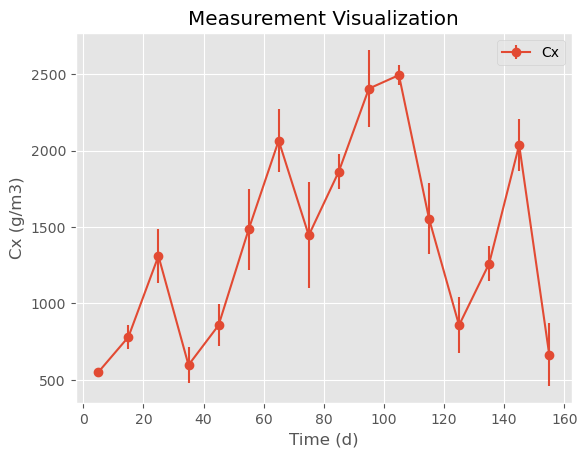

In [ ]:
for measurement in data_all:
    plt.figure()
    plt.errorbar(measurement.timepoints, measurement.values, yerr=measurement.errors, fmt='o-', label=measurement.name)
    plt.xlabel('Time (d)')
    plt.ylabel('Cx (g/m3)')
    plt.title('Measurement Visualization')
    plt.legend()
    plt.grid(True)

plt.show()

In [4]:
def make_experiment(caretaker:Caretaker, tfinal:float, samples:int=1, show:bool=True):
    
    simulation = caretaker.simulate(t=tfinal)
    data = data_all
    if show:
        _ncols = len(set([_item.name for _item in simulation]))
        _ = Visualization.show_kinetic_data(simulation, ncols=_ncols)
        _ncols = len(set([_item.name for _item in data]))
        _ = Visualization.show_kinetic_data(data, ncols=_ncols)

    return data, simulation

`I` and `T` are included as states with derivative zero, so events can switch them. At t = 10, 20, 30 and so on, `change_states` sets the new I and T. One 160-day simulation therefore reproduces the whole schedule: 4 light levels × 4 temperatures, 10 days each, measured on day 5 of each step.



In [ ]:
# Defines the model class
class milliPBR_TI_13(BioprocessModel):
    
    def rhs(self, t, y, sw):
            
        # Unpacks the state vector. I only have a differential equation, for Cx. I add I and T so that I can change them in the events.
        Cx, I, T = y         
        
        # fixed parameters
        tau = 1.3      # day
        D = 1/tau
           
        # Unpacks the model parameters.
        ka1 = self.model_parameters['ka1']
        mumax = self.model_parameters['mumax'] 
        KI = self.model_parameters['KI'] 
        Iopt = self.model_parameters['Iopt']
        nn = self.model_parameters['nn']
        mue = self.model_parameters['mue']
        Tmin = self.model_parameters['Tmin']
        Tmax = self.model_parameters['Tmax']
        Topt = self.model_parameters['Topt']
        
        ka1n = self.model_parameters['ka1n']
        mumaxn = self.model_parameters['mumaxn'] 
        KIn = self.model_parameters['KIn'] 
        Ioptn = self.model_parameters['Ioptn']
        muen = self.model_parameters['muen']
        Tmaxn = self.model_parameters['Tmaxn']
        Toptn = self.model_parameters['Toptn']
            
        z = np.linspace(0, 0.015, 100)
        
        aa=27.04665532
        bb=0.07364861
        kk=2.53620448
        k2=0.08380622
        
        ka = aa/((bb)*T**kk+I)+k2
        
        Iz = I*np.exp(-(ka1*ka1n*ka)*Cx*z)
             
        fiT = (T-Tmax*Tmaxn)*(T-Tmin)**2/((Topt*Toptn-Tmin)*((Topt*Toptn-Tmin)*(T-Topt*Toptn) - (Topt*Toptn-Tmax*Tmaxn)*(Topt*Toptn+Tmin-2*T)))

        KIT=KI*KIn
        muI = mumax*mumaxn*Iz/(Iz+KIT*(1-Iz/(Iopt*Ioptn))**2)

        muIT = muI*fiT**nn
        
        rx_z = muIT*Cx-mue*muen*Cx
        rx_av = simps(rx_z,z)/(z[-1] - z[0])
    
        # Define derivatives
    
        dCxdt = rx_av-D*Cx
        dIdt = 0
        dTdt = 0
           
        # Returns the derivative as list (or numpy array).
        # The order corresponds to the state vector.
        return [dCxdt, dIdt, dTdt]
    
    def state_events(self, t, y, sw):
        
        # Unpacks the state vector. The states are alphabetically ordered.
        Cx, I, T = y         
        
        # Unpacks the event parameters
        t_change = self.model_parameters['t_change']

        
        # Light changes
        event_I_300 = t-4*t_change           #0    t=400
        event_I_600 = t-4*t_change*2         #1    t=800
        event_I_900 = t-4*t_change*3         #2    t=1200
        event_I_1200 = t-4*t_change*4         #15    t=1200
        
        # T changes
        event_T24_1 = t-t_change           #3
        event_T24_2 = t-t_change*5         #4
        event_T24_3 = t-t_change*9         #5
        event_T24_4 = t-t_change*13        #6
        
        event_T30_1 = t-t_change*2         #7
        event_T30_2 = t-t_change*6         #8
        event_T30_3 = t-t_change*10        #9
        event_T30_4 = t-t_change*14        #10
        
        event_T36_1 = t-t_change*3         #11
        event_T36_2 = t-t_change*7         #12
        event_T36_3 = t-t_change*11        #13
        event_T36_4 = t-t_change*15        #14
        
        event_Cx = t-t_change
        
        events = [event_I_300, event_I_600, event_I_900, event_T24_1, 
                  event_T24_2, event_T24_3, event_T24_4, event_T30_1, 
                  event_T30_2, event_T30_3, event_T30_4, event_T36_1, 
                  event_T36_2, event_T36_3, event_T36_4, event_I_1200,
                  event_Cx]
        
        # Events must be returned as list or numpy array
        return events
    
    
    # This method modifies the values of the model states, 
    # so that the integration starts again, but with different initial values
    def change_states(self, t, y, sw):

        # Unpacks the state vector. The states are alphabetically ordered.
        Cx, I, T = y  
        Cx_add = self.model_parameters['Cx_add']
        # In case the second event is hit, modify the state 'A'


        # Lights:
        
        if sw[0]:
            I = 300                       
        if sw[1]:
            I = 600           
        if sw[2]:
            I = 900
            
        #1st T cycle
        if sw[3]:           
            Cx = Cx_add
            T = 24
        if sw[7]:
            T = 30
        if sw[11]:
            T = 36
            
        #2nd T cycle  
        if sw[0]:
            T=18
        if sw[4]:
            T=24
        if sw[8]:
            T=30
        if sw[12]:
            T=36
            
        #3rd T cycle  
        if sw[1]:
            T=18
        if sw[5]:
            T=24
        if sw[9]:
            T=30
        if sw[13]:
            T=36
        
        #4th T cycle  
        if sw[2]:
            T=18
        if sw[6]:
            T=24
        if sw[10]:
            T=30
        if sw[14]:
            T=36
            
        
        return [Cx, I, T]
    
    
# Defines a dictionary for the initial values.
# The keys corresponds to the model states
initial_values = {
    'Cx0': 2000.0,
    'I0': 150,
    'T0': 18, 
}

# Defines a dictionary for the model parameters
# The keys match those variable names used in the model class
model_parameters = {
    'ka1': 0.7,
    'mumax': 1.4366672720626508,
    'KI': 61.469165873608326,
    'Iopt': 193.852288943783,
    'nn': 0.5,   
    'mue': 0.45,                   
    'Tmin': 0.1,
    'Tmax': 42.2,
    'Topt': 29.4, 
    
    'ka1n': 1,
    'mumaxn': 1,
    'KIn': 1,
    'Ioptn': 1,
    'muen': 1,                 
    'Tminn': 1,
    'Tmaxn': 1,
    'Toptn': 1, 
    
    't_change': 10,
    'Cx_min' : 500.0,
    'Cx_add' : 2000.0,
}



In [56]:
caretaker = Caretaker(
    bioprocess_model_class=milliPBR_TI_13, 
    model_parameters=model_parameters, 
    initial_values=initial_values,
    replicate_ids=['1st'],
)

In [57]:
# Define mapping to make the initial values local parameters for the replicate_id
mappings = [
    ParameterMapper(replicate_id='1st', global_name='Cx0', value=2000.0),
    ParameterMapper(replicate_id='1st', global_name='I0', value=150),
    ParameterMapper(replicate_id='1st', global_name='T0', value=18),
]
caretaker.apply_mappings(mappings)

# Save for later comparison
_pars_for_comp = caretaker._get_all_parameters()

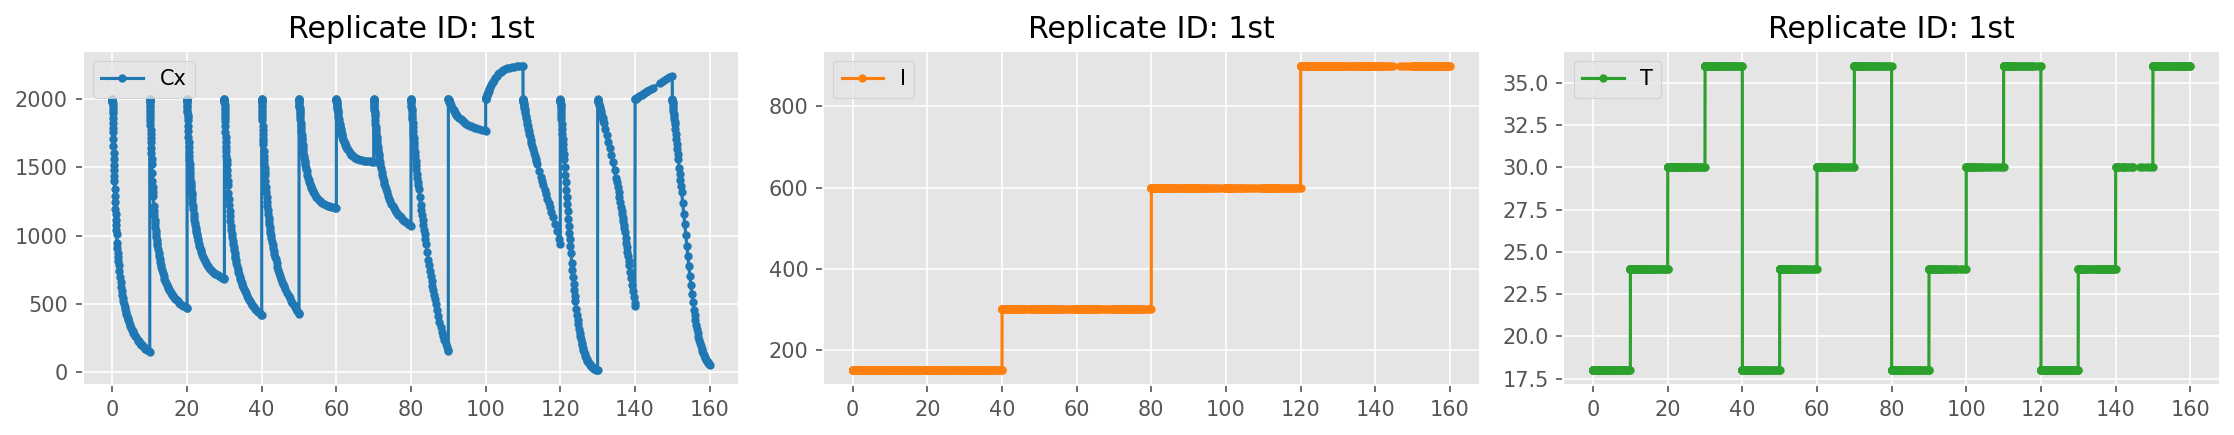

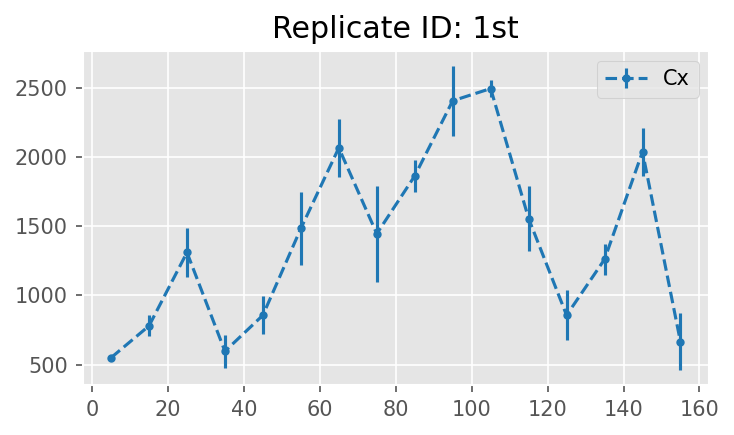

In [59]:
data, simulation = make_experiment(caretaker, tfinal=160)

In [60]:
# Parameter estimation

# Defines the unknowns to be estimated, as well as corresponding bounds
unknowns = [

    'mumaxn',
    'KIn',
    'Ioptn',
    
    'ka1n',
    'nn',
    
    'Tmaxn',
    'Toptn',


]

bounds = [

    (0.4, 1.7),
    (0.4, 1.7),
    (0.4, 1.7),
    
    (0.4, 1.7),
    (0.01, 1),
    
    (0.85, 1.1),
    (0.78, 1.16),

]


In [ ]:
estimates, est_info = caretaker.estimate_parallel(
    unknowns=unknowns,
    bounds=bounds,
    measurements=data_all, 
    report_level=3, # We set the report_level to see some output during the optimization process.

)

Creating archipelago with 16 islands. May take some time...


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   2 out of  16 | elapsed:   56.9s remaining:  6.7min
[Parallel(n_jobs=16)]: Done  16 out of  16 | elapsed:  1.0min finished


Running 5 evolutions for all 16 islands of the archipelago...

-------------Finished evolution 1-------------
Current best loss: 111.87945012989738
Average loss among the islands: 126.275148 +/- 11.872377 (9.401990 %)
-------------Finished evolution 2-------------
Current best loss: 109.92608544008559
Average loss among the islands: 114.925039 +/- 4.081066 (3.551067 %)
-------------Finished evolution 3-------------
Current best loss: 107.55371896818743
Average loss among the islands: 111.712013 +/- 2.081094 (1.862910 %)
-------------Finished evolution 4-------------
Current best loss: 106.01692558615784
Average loss among the islands: 109.246269 +/- 1.806705 (1.653791 %)
-------------Finished evolution 5-------------
Current best loss: 104.40515545256265
Average loss among the islands: 107.724771 +/- 1.962689 (1.821948 %)

Completed 5 evolution runs.

Estimated parameters:
Ioptn: 1.0055122549617586
ka1n: 0.8474769968135814
KIn: 0.899657270644583
mumaxn: 0.9873721035322528
nn: 0.1016202

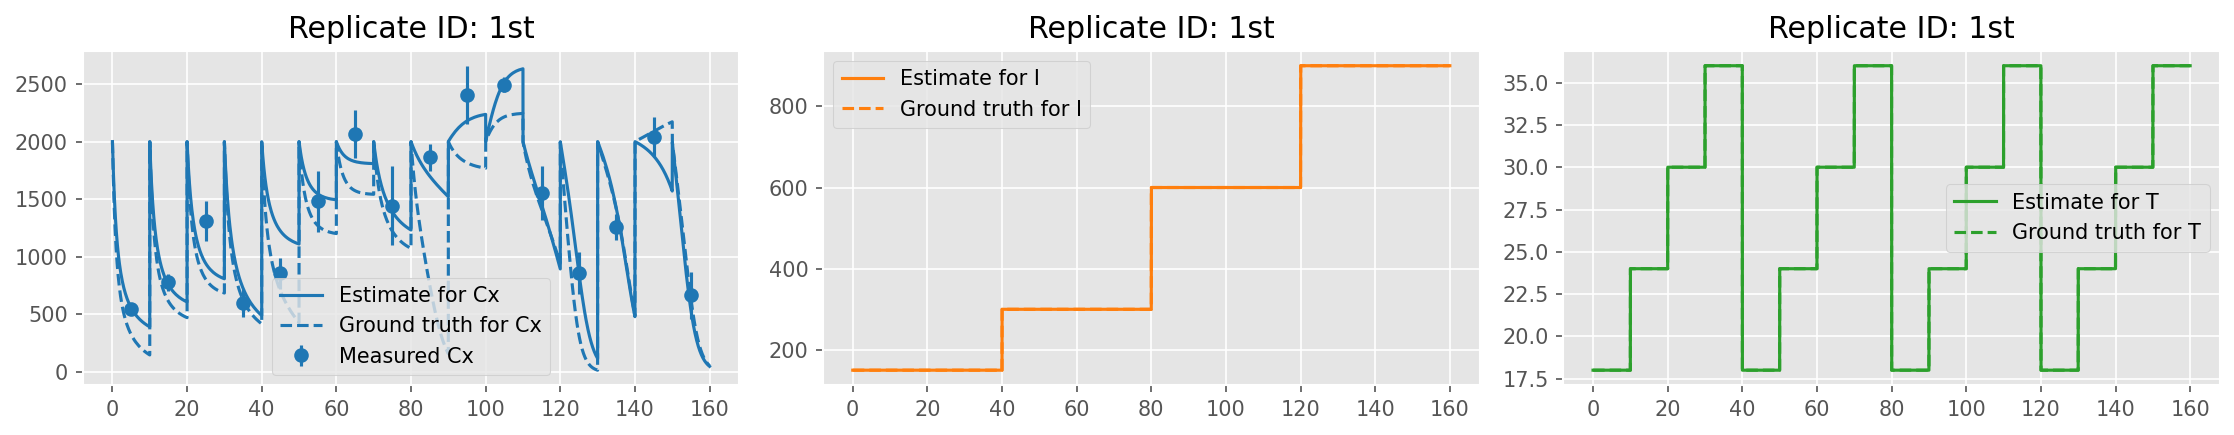

In [62]:
# compare

_ = Visualization.compare_estimates(parameters=estimates, measurements=data_all, caretaker=caretaker, truth=simulation)


In [63]:
uncerts = caretaker.get_parameter_uncertainties(estimates, measurements=data, report_level=1)


Estimated parameters:
----------
Ioptn: 1.01e+00 +/- 8.56e-02 (8.52 %)
ka1n: 8.47e-01 +/- 8.26e-02 (9.75 %)
KIn: 9.00e-01 +/- 1.69e-01 (18.80 %)
mumaxn: 9.87e-01 +/- 4.22e-02 (4.27 %)
nn: 1.02e-01 +/- 4.31e-02 (42.40 %)
Tmaxn: 8.63e-01 +/- 2.31e-02 (2.67 %)
Toptn: 1.07e+00 +/- 1.15e-01 (10.71 %)
